In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

In [2]:
def f(x0, x1, x2, x3):
    return (x0 + 10*x1)**2 + 5*(x2 - x3)**2 + (x1 - 2*x2)**4 + 10*(x0 - x3)**4

##### Data

Powell est en 4D : on ne peut pas l'afficher entièrement. On trace une coupe : on fixe x2 = x3 = 0 et on fait varier x0 et x1.

In [3]:
x = np.arange(-5, 5, 0.01)
y = np.arange(-5, 5, 0.01)

X, Y = np.meshgrid(x, y)

Z = f(X, Y, 0, 0)

##### Affichage HeatMap (coupe x2 = x3 = 0)

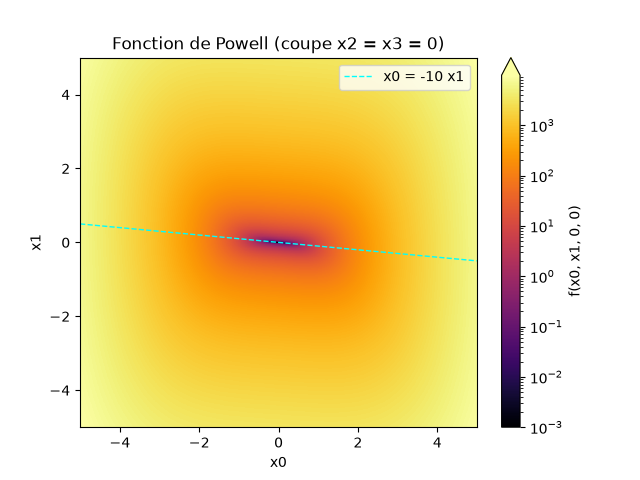

In [4]:
fig, ax = plt.subplots()

norm = LogNorm(vmin=1e-3, vmax=Z.max())
pcm = ax.pcolormesh(X, Y, Z, norm=norm, cmap="inferno", shading="auto")
fig.colorbar(pcm, ax=ax, extend="max", label="f(x0, x1, 0, 0)")

ax.plot(x, -x/10, "--", c="cyan", lw=1, label="x0 = -10 x1")
ax.set_ylim(-5, 5)

ax.set_xlabel("x0")
ax.set_ylabel("x1")
ax.set_title("Fonction de Powell (coupe x2 = x3 = 0)")
ax.legend(loc="upper right")

plt.show()

##### Recherche du minimum

In [5]:
from algo.neldermead import NelderMead
from utils.point import Point

def simplexe_initial(x, h=0.5):
    points = [Point(list(x))]
    for i in range(len(x)):
        y = list(x)
        y[i] += h
        points.append(Point(y))
    return points

def _f(p: Point)->float:
    return f(*p.values)

algo = NelderMead(simplexe_initial([3, -1, 0, 1]), _f)
algo.compute(500)

In [6]:
operations = ["Reflexion", "Expansion", "Contraction", "Homothetie"]
etats = [s for s in algo.history if s["operation"] in operations]

meilleurs = [min(s["points"], key=_f) for s in etats]
valeurs = [_f(p) for p in meilleurs]
iterations = [s["step"] for s in etats]

print("Meilleur point :", meilleurs[-1])
print("f =", valeurs[-1])

Meilleur point : Point([5.6910960337651514e-09, -5.691096025338994e-10, 3.9361406108967685e-09, 3.936140621933785e-09], Dimension: 4)
f = 5.8525059995016986e-33


##### Convergence de f

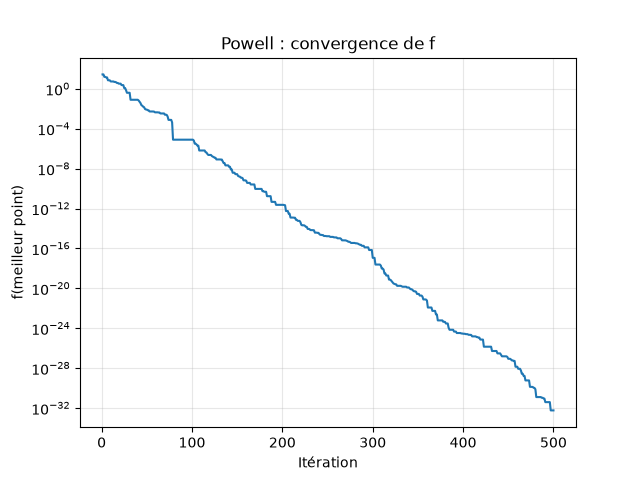

In [7]:
fig, ax = plt.subplots()

ax.semilogy(iterations, valeurs)
ax.set_xlabel("Itération")
ax.set_ylabel("f(meilleur point)")
ax.set_title("Powell : convergence de f")
ax.grid(True, which="both", alpha=0.3)

plt.show()

##### Coordonnées du meilleur point (le minimum est en 0)

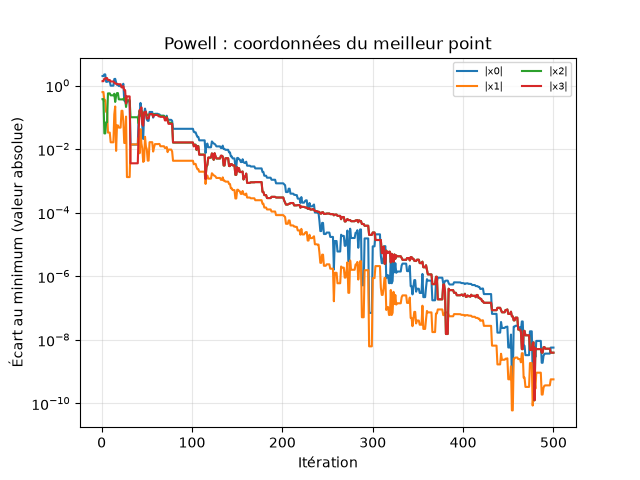

In [8]:
fig, ax = plt.subplots()

for i in range(4):
    ax.semilogy(iterations, [abs(p[i]) for p in meilleurs], label=f"|x{i}|")

ax.set_xlabel("Itération")
ax.set_ylabel("Écart au minimum (valeur absolue)")
ax.set_title("Powell : coordonnées du meilleur point")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=7, ncol=2)

plt.show()